# C1_09_Test_Evaluation
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Model = the saved GRU from C1_08_Final_Model (gru_prev1_final.keras)

### Test evaluation of the final model

**Purpose:** runs the saved GRU (previous window + current window) once on the held-out test runs, reports how well it did, and checks whether it predicts changes or mostly "no change".

**Output:** the test predictions (`test_pred.npy` and `test_idx.npy`, saved in `c1_final_model\test_evaluation`). The charts are shown in the notebook. The model is not changed or retrained here.

## 1. Setup and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
from tensorflow import keras

# The same files the model was trained on
DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")
X_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_PATH = DATA_DIR / "y_labels_c1_v2.csv"
MODEL_DIR = DATA_DIR / "c1_final_model"                       # output of C1_08_Final_Model
TEST_DIR = MODEL_DIR / "test_evaluation"
TEST_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 30   # length of one window

## 2. Load data and build the common window set

In [13]:
X_flat = np.load(X_PATH).astype("float32")
y_df = pd.read_csv(Y_PATH)
assert len(X_flat) == len(y_df), "X and Y have different numbers of rows"

# Row number of every window, so earlier windows can be looked up by (file, start time)
row_of = pd.Series(np.arange(len(y_df)), index=pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"]]))
assert row_of.index.is_unique

prev1 = row_of.reindex(pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - WINDOW_SECONDS])).to_numpy()
prev2 = row_of.reindex(pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - 2 * WINDOW_SECONDS])).to_numpy()
has_both = ~np.isnan(prev1) & ~np.isnan(prev2)   # same window rule as training and validation
print(f"{len(y_df)} windows, {int(has_both.sum())} have both earlier windows")
# Kept for consistency: the input ablation (C1_04) needed two earlier windows, so the same rule is used for every set


197341 windows, 193591 have both earlier windows


## 3. Test windows

In [3]:
run_idx_all = y_df["run_idx"].to_numpy()
train_runs, test_runs = train_test_split(np.unique(run_idx_all), test_size=0.2, random_state=42)
trainval_idx = np.where(np.isin(run_idx_all, train_runs))[0]
trainval_runs = run_idx_all[trainval_idx]
fit_runs, val_runs = train_test_split(np.unique(trainval_runs), test_size=0.15, random_state=42)

fit_idx = trainval_idx[np.isin(trainval_runs, fit_runs) & has_both[trainval_idx]]
val_idx = trainval_idx[np.isin(trainval_runs, val_runs) & has_both[trainval_idx]]
test_idx = np.where(np.isin(run_idx_all, test_runs) & has_both)[0]

# Checks: the split matches the one the model was trained with, and the test windows are separate from fit and validation
assert np.array_equal(val_idx, np.load(MODEL_DIR / "val_idx.npy")), "validation windows differ from training: the split or files have changed"
assert not set(test_runs) & set(fit_runs) and not set(test_runs) & set(val_runs)
assert not set(test_idx) & set(fit_idx) and not set(test_idx) & set(val_idx)
print(f"Test: {len(test_idx)} windows from {len(test_runs)} runs (the split reproduces the training validation windows)")

saved = np.load(MODEL_DIR / "scaler_and_classes.npz")      # scaling and class order saved with the model
classes = saved["classes"]
class_to_int = {c: i for i, c in enumerate(classes)}
assert set(y_df["c1_target"].unique()) <= set(classes)
y_fit = np.array([class_to_int[c] for c in y_df["c1_target"].to_numpy()[fit_idx]])
y_test = np.array([class_to_int[c] for c in y_df["c1_target"].to_numpy()[test_idx]])


Test: 39080 windows from 375 runs (the split reproduces the training validation windows)


## 4. Predict on the test windows

In [4]:
pred_path = TEST_DIR / "test_pred.npy"

if pred_path.exists():
    # Already predicted: load the saved predictions, the model is not run again (delete test_pred.npy only to redo it on purpose)
    test_pred = np.load(pred_path)
    assert np.array_equal(np.load(TEST_DIR / "test_idx.npy"), test_idx)
    print("Test predictions already exist: loaded, not recomputed")
else:
    previous_window = np.stack([X_flat[prev1[test_idx].astype(int), c:c + 30] for c in (0, 30, 60, 90)], axis=-1)
    current_window = np.stack([X_flat[test_idx, c:c + 30] for c in (0, 30, 60, 90)], axis=-1)
    X_test_seq = np.concatenate([previous_window, current_window], axis=1)               # previous window first
    X_test_seq = ((X_test_seq - saved["mean"]) / saved["scale"]).astype("float32")       # the saved scaling (not re-fitted on test data)

    model = keras.models.load_model(MODEL_DIR / "gru_prev1_final.keras")
    test_pred = model.predict(X_test_seq, batch_size=1024, verbose=0).argmax(axis=1)
    np.save(pred_path, test_pred)
    np.save(TEST_DIR / "test_idx.npy", test_idx)
    print("Test predictions made and saved")


Test predictions already exist: loaded, not recomputed


## 5. Test results

In [5]:
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
naive_acc = float(np.mean(y_test == np.bincount(y_fit).argmax()))       # always guess the biggest class in the fit data

run_record = json.load(open(MODEL_DIR / "run_record.json"))
val_acc = run_record["results"]["validation_accuracy"]
val_f1 = run_record["results"]["validation_macro_f1"]

print(f"Test accuracy: {test_acc:.3f} | macro-F1: {test_f1:.3f} | naive baseline: {naive_acc:.3f}")
print(f"Validation accuracy: {val_acc:.3f} | macro-F1: {val_f1:.3f}")
print(classification_report(y_test, test_pred, target_names=classes, zero_division=0))


Test accuracy: 0.605 | macro-F1: 0.630 | naive baseline: 0.376
Validation accuracy: 0.611 | macro-F1: 0.654
              precision    recall  f1-score   support

        Base       0.56      0.68      0.61     14705
   Declining       0.67      0.55      0.60     12849
   Improving       0.62      0.56      0.59     10806
    Recovery       0.75      0.69      0.72       720

    accuracy                           0.60     39080
   macro avg       0.65      0.62      0.63     39080
weighted avg       0.61      0.60      0.60     39080



### Confusion matrix (test)

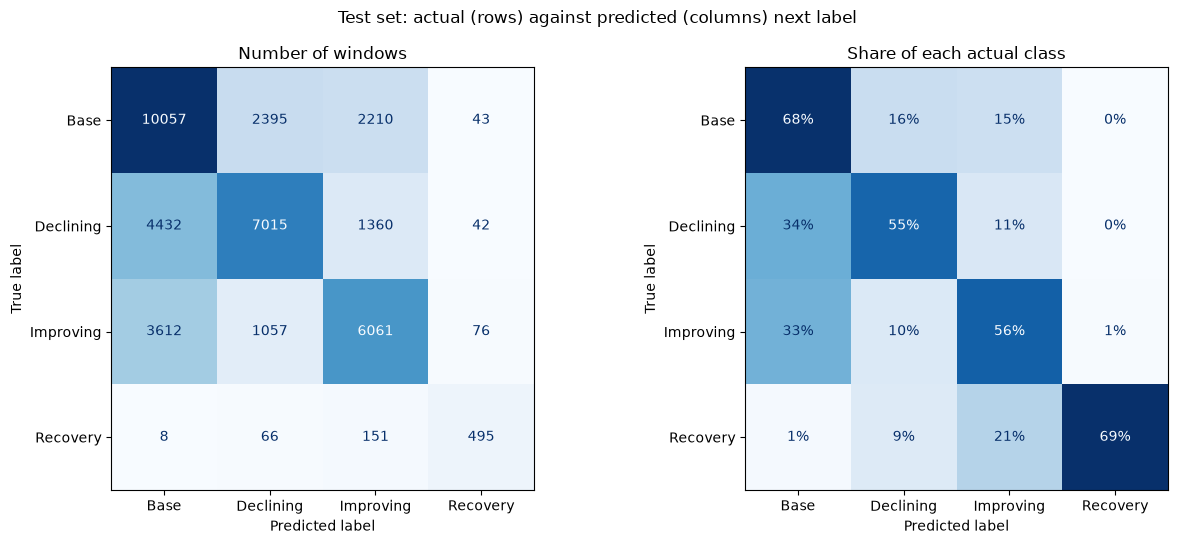

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=classes, ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Number of windows")
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=classes, normalize="true", ax=axes[1], cmap="Blues", colorbar=False, values_format=".0%")
axes[1].set_title("Share of each actual class")
fig.suptitle("Test set: actual (rows) against predicted (columns) next label")
plt.tight_layout()
plt.show()


### Scores for each class

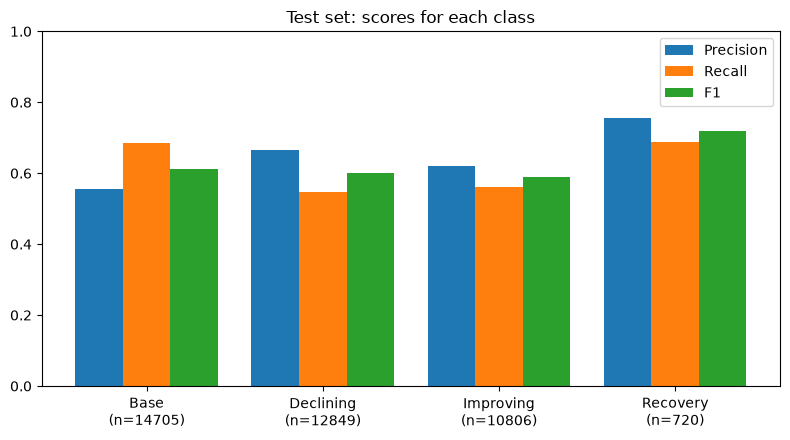

In [7]:
precision, recall, f1, support = precision_recall_fscore_support(y_test, test_pred, labels=np.arange(len(classes)), zero_division=0)
x = np.arange(len(classes))

plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.27, precision, width=0.27, label="Precision")
plt.bar(x, recall, width=0.27, label="Recall")
plt.bar(x + 0.27, f1, width=0.27, label="F1")
plt.xticks(x, [f"{c}\n(n={n})" for c, n in zip(classes, support)])
plt.ylim(0, 1)
plt.title("Test set: scores for each class")
plt.legend()
plt.tight_layout()
plt.show()


### Validation vs Test

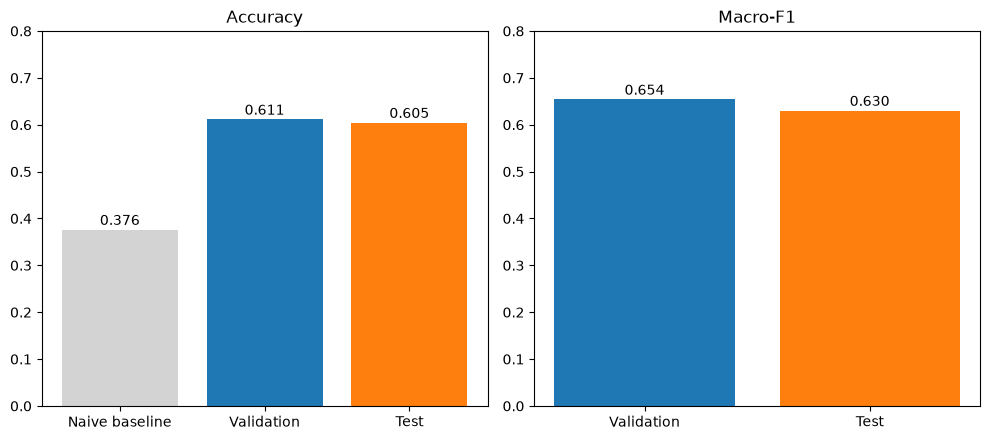

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].bar(["Naive baseline", "Validation", "Test"], [naive_acc, val_acc, test_acc], color=["lightgrey", "tab:blue", "tab:orange"])
for i, v in enumerate([naive_acc, val_acc, test_acc]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center")
axes[0].set_ylim(0, 0.8)
axes[0].set_title("Accuracy")
axes[1].bar(["Validation", "Test"], [val_f1, test_f1], color=["tab:blue", "tab:orange"])
for i, v in enumerate([val_f1, test_f1]):
    axes[1].text(i, v + 0.01, f"{v:.3f}", ha="center")
axes[1].set_ylim(0, 0.8)
axes[1].set_title("Macro-F1")
plt.tight_layout()
plt.show()


## 6. Does the model predict changes, or mostly "no change"?

A change is a window whose next label differs from its own (current) label. The windows file gives each test window's own label. The model never sees it.


In [9]:
own_label = y_df.set_index(["file_path", "start_s"])["c1_target"]       # c1_target is the label of the NEXT window

test_files = y_df["file_path"].to_numpy()[test_idx]
test_starts = y_df["start_s"].to_numpy()[test_idx]
# a window's own label is the c1_target of the window 30 seconds before it
current = own_label.reindex(pd.MultiIndex.from_arrays([test_files, test_starts - WINDOW_SECONDS])).to_numpy()

tr = pd.DataFrame({"current": current, "actual_next": classes[y_test], "predicted_next": classes[test_pred]})
tr = tr[pd.notna(tr["current"])].copy()        # a window with no own label has no change to look at
tr["correct"] = tr["actual_next"] == tr["predicted_next"]
print(f"{len(tr)} test windows have a current label")

39080 test windows have a current label


Share of windows where the label really changes: 0.308
Share of windows where the model predicts a change: 0.410
Real changes where the model predicted some change: 0.615
Real changes where the model named the right new label: 0.431
Windows with no change where the model predicted one (false alarms): 0.318


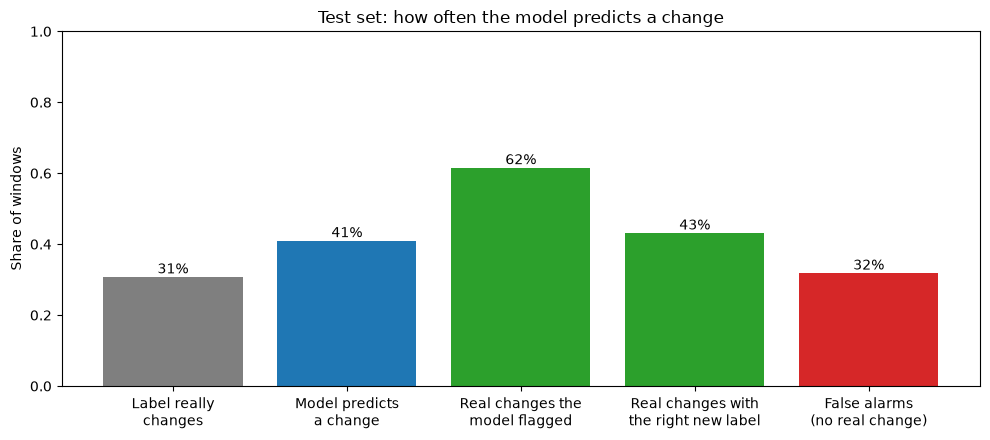

In [10]:
tr["says_change"] = tr["predicted_next"] != tr["current"]      # the model predicts a different label from the current one
tr["is_change"] = tr["actual_next"] != tr["current"]           # the label really does change

real_change_rate = tr["is_change"].mean()                      # share of windows where the label really changes
predicted_change_rate = tr["says_change"].mean()               # share of windows where the model predicts a change
caught = tr.loc[tr["is_change"], "says_change"].mean()         # real changes where the model also predicted some change
named_right = tr.loc[tr["is_change"], "correct"].mean()        # real changes where the model named the right new label
false_alarm = tr.loc[~tr["is_change"], "says_change"].mean()   # no real change, but the model predicted one

print(f"Share of windows where the label really changes: {real_change_rate:.3f}")
print(f"Share of windows where the model predicts a change: {predicted_change_rate:.3f}")
print(f"Real changes where the model predicted some change: {caught:.3f}")
print(f"Real changes where the model named the right new label: {named_right:.3f}")
print(f"Windows with no change where the model predicted one (false alarms): {false_alarm:.3f}")

names = ["Label really\nchanges", "Model predicts\na change", "Real changes the\nmodel flagged", "Real changes with\nthe right new label", "False alarms\n(no real change)"]
values = [real_change_rate, predicted_change_rate, caught, named_right, false_alarm]
plt.figure(figsize=(10, 4.5))
plt.bar(names, values, color=["tab:grey", "tab:blue", "tab:green", "tab:green", "tab:red"])
for i, v in enumerate(values):
    plt.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.ylim(0, 1)
plt.ylabel("Share of windows")
plt.title("Test set: how often the model predicts a change")
plt.tight_layout()
plt.show()
